# 09 Clustervalidierung: Betriebszustand oder Jahreszeit?

Teil 3: Clustering

**Worum es geht**
- Jede Betriebsstunde einer HAST wird einzeln geclustert, nicht die Station als Ganzes (K-Means, k = 5, fünf Betriebszustände).
- Geprüft wird, ob das trägt: Stabilität, Jahreszeit und Abgleich mit den Begehungen.
- Bilden die Stundencluster Betriebszustände ab oder nur Jahres- und Tageszeit? (Abschnitte 1 bis 7)
- Was ändern Merkmalsgewichtung, BHKW-Ausschluss und Leistungsklassen? (Abschnitte 8 bis 10)

**Daten**
- liest: `data/processed/real_meters/` (Stundenwerte), Außentemperatur aus dem DWD-Cache, `data/processed/inspections_tidy.csv`, `data/processed/hast_features.csv`, `data/raw/Zuordnung.xlsx`, Anschlusswerte aus `Nodes_Edges.ods`
- schreibt: `data/processed/clustervalidierung.csv` und `data/processed/clustervalidierung.json`
- vorher ausführen: Notebook 00; `inspections_tidy.csv` entsteht mit `python -m src.main`

**Code**
- Logik in `src/clustervalidierung.py`, Tests in `tests/test_clustervalidierung.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "processed").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import clustervalidierung as cvl  #noqa: E402
from src import features as ft  #noqa: E402
from src import load_begehungen as lb  #noqa: E402
from src import load_data as ld  #noqa: E402
from src import nb00_daten as nb00  #noqa: E402
from src import weather  #noqa: E402
from src.load_data import _normalize_address  #noqa: E402

METER_DIR = ROOT / "data" / "processed" / "real_meters"
INSPECTIONS_PATH = ROOT / "data" / "processed" / "inspections_tidy.csv"
ZUORDNUNG_PATH = ROOT / "data" / "raw" / "Zuordnung.xlsx"
for pfad in (METER_DIR, INSPECTIONS_PATH, ZUORDNUNG_PATH):
    if not pfad.exists():
        raise FileNotFoundError(f"{pfad} nicht gefunden")

SEED = cvl.SEED
F = cvl.BETRIEBS_FEATURES
print("Merkmalsraum der Stundencluster:", F)

Merkmalsraum der Stundencluster: ['power_norm', 'flow_norm', 'dt', 'vl', 'rt']


## 1 Stundenpanel

- Stundenpanel = alle Betriebsstunden aller Zähler in einer Tabelle.
- Merkmale: `power_norm` und `flow_norm` (auf das stationseigene 95. Perzentil normiert, weil der Anschlusswert bei 8 von 93 Zählern fehlt), Spreizung (`dt`, Vorlauf minus Rücklauf), Vorlauf (`vl`) und Rücklauf (`rt`).
- Ausgeschlossen: weniger als 100 vollständige Stunden (1 Zähler: 58202380, einer der Ausreißer aus Notebook 07).
- Ergebnis: 1 676 633 Betriebsstunden von 92 Zählern, 01.11.2021 bis 20.07.2026.

In [2]:
t0 = time.time()
panel, ausschluss = cvl.lade_stundenpanel(METER_DIR)
print(f"{len(panel):,} Betriebsstunden von {panel['Zählernummer'].nunique()} Zählern "
      f"({time.time() - t0:.0f} s)")
print(f"Zeitraum {panel['timestamp'].min():%Y-%m-%d} bis {panel['timestamp'].max():%Y-%m-%d}")
print("\nAusschlussbilanz:")
display(ausschluss)

1,676,633 Betriebsstunden von 92 Zählern (1 s)
Zeitraum 2021-11-01 bis 2026-07-20

Ausschlussbilanz:


,Zählernummer,n_stunden,n_zeilen_roh,grund
0,58202380,0,22167,weniger als 100 vollständige Stunden


In [3]:
temp = weather.load_outdoor_temperature(panel["timestamp"].min(), panel["timestamp"].max(),
                                        allow_download=False)
panel = cvl.mit_kontext(panel, temp)
print(f"Außentemperatur aus dem DWD-Cache, {temp['t_out'].isna().sum()} Fehlwerte "
      f"auf {len(temp):,} Stunden")
print(f"Stunden ohne Temperaturwert im Panel: {panel['t_out'].isna().mean():.4%}")
print("\nStundenanteil je Saisonsegment (das ist die Basisrate für alles Folgende):")
display(panel["season"].value_counts(normalize=True).round(3).to_frame("Anteil"))

Außentemperatur aus dem DWD-Cache, 9 Fehlwerte auf 41,312 Stunden
Stunden ohne Temperaturwert im Panel: 0.0128%

Stundenanteil je Saisonsegment (das ist die Basisrate für alles Folgende):


,Anteil
season,
sommer,0.316
kernwinter,0.281
uebergang_frueh,0.212
uebergang_spaet,0.191


## 2 Stundencluster mit k = 5

- Durchlauf k = 2 bis 8 auf dem Panel aus `src/`, mit dokumentierter Ausschlussregel.
- Silhouette (Trennschärfe von −1 bis 1) auf einer Stichprobe von 20 000 Stunden.

Matrix: (1676633, 5)


,k,silhouette
0,2,0.327
1,3,0.360
2,4,0.399
3,5,0.403
4,6,0.400
5,7,0.366
6,8,0.363


110 s


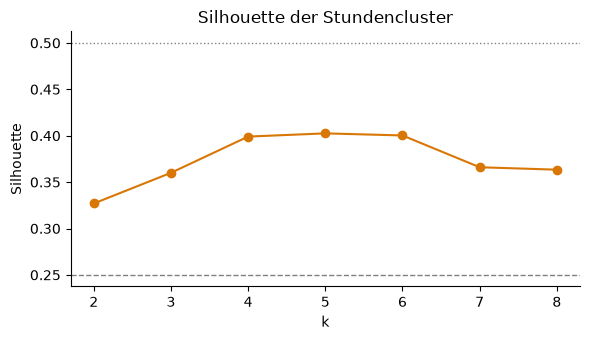

In [4]:
X = StandardScaler().fit_transform(panel[F])
print("Matrix:", X.shape)

t0 = time.time()
sweep = []
for k in range(2, 9):
    lab = cvl.fit_minibatch_kmeans(X, k, n_init=3)
    sweep.append({"k": k, "silhouette": cvl.silhouette_stichprobe(X, lab, 20000)})
sweep = pd.DataFrame(sweep)
display(sweep.round(3))
print(f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sweep["k"], sweep["silhouette"], marker="o", color="#D97706")
ax.axhline(0.25, color="grey", lw=1, ls="--")
ax.axhline(0.5, color="grey", lw=1, ls=":")
ax.set(title="Silhouette der Stundencluster", xlabel="k", ylabel="Silhouette")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

In [5]:
K = 5
labels = cvl.fit_minibatch_kmeans(X, K, n_init=10)
panel["cluster"] = labels
sil_voll = cvl.silhouette_stichprobe(X, labels, 20000)
print(f"k={K}: Silhouette {sil_voll:.3f}")

profil_voll = cvl.zentroid_profil(panel[F].to_numpy(), labels, F)
print("\nClusterprofile in Originaleinheiten (power_norm und flow_norm relativ zum "
      "stationseigenen p95, Temperaturen in °C):")
display(profil_voll.round(2))

k=5: Silhouette 0.399

Clusterprofile in Originaleinheiten (power_norm und flow_norm relativ zum stationseigenen p95, Temperaturen in °C):


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.07,0.09,11.90,65.76,53.82,416380,24.8
1,0.21,0.76,4.15,75.17,70.98,219361,13.1
2,0.32,0.21,33.76,67.23,33.42,417773,24.9
3,0.00,0.01,3.34,35.16,31.79,322005,19.2
4,0.89,0.84,23.26,73.53,50.23,301114,18.0


- Silhouette-Maximum bei k = 5 (0,403 im Durchlauf, 0,399 im finalen Lauf), k = 4 und k = 6 mit 0,399 und 0,400 dicht dahinter. Clusternummern können zwischen Läufen wechseln.

| Cluster | Zustand | Kennzeichen | Anteil Stunden |
|---|---|---|---|
| 3 | Stillstand | Leistung praktisch 0, Vorlauf 35 °C | 19 % |
| 2 | effizienter Normalbetrieb | Spreizung 33,8 K, Rücklauf 33 °C | 25 % |
| 0 | Teillast | Leistung 0,07, Spreizung 11,9 K, Rücklauf 54 °C | 25 % |
| 4 | Hochlast | Leistung 0,89, Spreizung 23,3 K | 18 % |
| 1 | Verdacht hydraulischer Kurzschluss | Durchfluss 0,76 bei Leistung 0,21, Spreizung 4,2 K, Rücklauf 71,0 °C | 13 % |

- Cluster 1 passt zu Kurzschluss, offenem Ventil oder defekter Regelung; die Ursache zeigt die Messung nicht.

## 3 Stabilität

- Bootstrap-Refit wie in Notebook 08: Stichprobe ziehen (50 000 Zeilen je Lauf), neu clustern, Labels über das nächste Zentrum auf alle Stunden übertragen.
- Vergleich mit der Referenz über den ARI (Adjusted Rand Index): 1 = gleiche Aufteilung, 0 = Zufallsniveau.

In [6]:
def fit_stunden(Xb, k):
    return cvl.fit_minibatch_kmeans(Xb, k, n_init=3)


t0 = time.time()
stab = []
for k in (3, 4, 5, 6):
    r = cvl.bootstrap_ari(fit_stunden, X, k, n_boot=25 if k == K else 15,
                          stichprobe=50000)
    stab.append({"k": k, **r.to_dict()})
stab = pd.DataFrame(stab)
display(stab.round(3))
print(f"{time.time() - t0:.0f} s")
ari_stunden = float(stab.loc[stab["k"] == K, "ari_mean"].iloc[0])
print(f"\nBootstrap-ARI bei k={K}: {ari_stunden:.3f} "
      "(Notebook 04 auf Stationsebene: 0,71 bzw. 0,60 bei k=3)")

,k,ari_mean,ari_std,ari_min,n_laeufe
0,3,0.653,0.113,0.485,15.0
1,4,0.805,0.199,0.413,15.0
2,5,0.851,0.117,0.509,25.0
3,6,0.736,0.113,0.620,15.0


7 s

Bootstrap-ARI bei k=5: 0.851 (Notebook 04 auf Stationsebene: 0,71 bzw. 0,60 bei k=3)


- k = 5: ARI 0,851, k = 4 knapp dahinter (0,805), k = 3 (0,653) und k = 6 (0,736) darunter. Streuung 0,12, schlechtester Lauf 0,51.
- Bei so vielen Punkten ist hohe Stabilität zu erwarten. Sie zeigt Unabhängigkeit vom Seed, nicht fachliche Bedeutung.

## 4 Saison- und Tageszeitkontrolle

- Wie stark hängt das Cluster an Saisonsegment, Monat und Stunde?
- Cramérs V = Stärke des Zusammenhangs zweier Kategorien (0 = keiner, 1 = vollständig). AMI (Adjusted Mutual Information) = geteilte Information, bereinigt um Zufall.
- Lift = Anteil eines Segments im Cluster geteilt durch seinen Anteil an allen Stunden (Basis: Sommer 31,6 %, Kernwinter 28,1 %).

In [7]:
basis = panel["season"].value_counts(normalize=True)
kt_saison = cvl.kontext_kreuztabelle(labels, panel["season"])
print("Anteil der Saisonsegmente je Cluster (Zeilensumme 1):")
display(kt_saison.round(3))
print("Lift gegen die Basisrate (1,0 = Cluster verteilt sich wie alle Stunden):")
display((kt_saison / basis).round(2))

kennwerte = pd.DataFrame([
    {"Kontextgröße": "Saisonsegment", "Cramers V": cvl.cramers_v(pd.crosstab(labels, panel["season"])),
     "AMI": adjusted_mutual_info_score(labels, panel["season"].astype(str))},
    {"Kontextgröße": "Monat", "Cramers V": cvl.cramers_v(pd.crosstab(labels, panel["monat"])),
     "AMI": adjusted_mutual_info_score(labels, panel["monat"].astype(str))},
    {"Kontextgröße": "Stunde des Tages", "Cramers V": cvl.cramers_v(pd.crosstab(labels, panel["stunde"])),
     "AMI": adjusted_mutual_info_score(labels, panel["stunde"].astype(str))},
])
display(kennwerte.round(3))

Anteil der Saisonsegmente je Cluster (Zeilensumme 1):


season,kernwinter,sommer,uebergang_frueh,uebergang_spaet
cluster,,,,
0,0.149,0.464,0.216,0.172
1,0.250,0.338,0.223,0.189
2,0.405,0.089,0.231,0.276
3,0.045,0.629,0.215,0.111
4,0.567,0.074,0.170,0.189


Lift gegen die Basisrate (1,0 = Cluster verteilt sich wie alle Stunden):


season,kernwinter,sommer,uebergang_frueh,uebergang_spaet
cluster,,,,
0,0.53,1.47,1.02,0.90
1,0.89,1.07,1.05,0.99
2,1.44,0.28,1.09,1.44
3,0.16,1.99,1.01,0.58
4,2.02,0.23,0.80,0.99


,Kontextgröße,Cramers V,AMI
0,Saisonsegment,0.310,0.107
1,Monat,0.297,0.097
2,Stunde des Tages,0.101,0.009


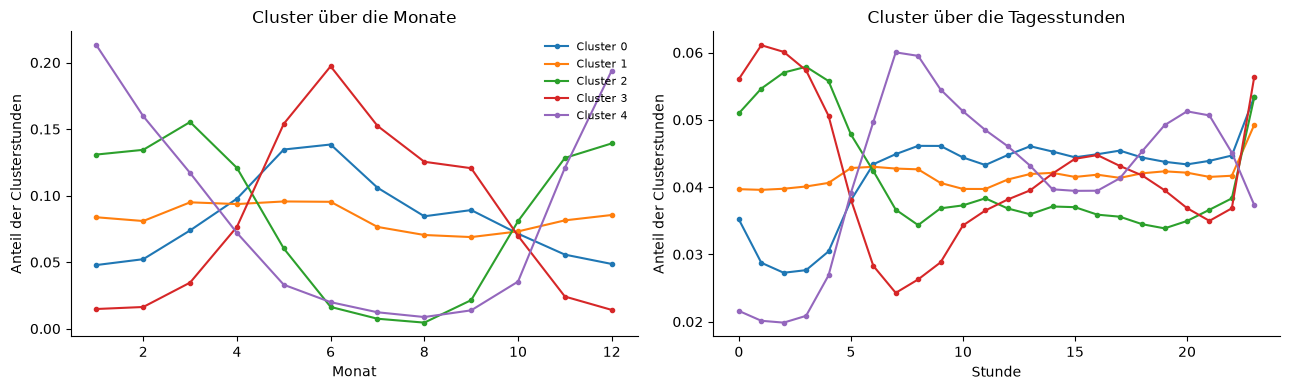

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
kt_monat = cvl.kontext_kreuztabelle(labels, panel["monat"])
kt_stunde = cvl.kontext_kreuztabelle(labels, panel["stunde"])
for ax, tab, titel, xlabel in [
        (axes[0], kt_monat, "Cluster über die Monate", "Monat"),
        (axes[1], kt_stunde, "Cluster über die Tagesstunden", "Stunde")]:
    for c in tab.index:
        ax.plot(tab.columns, tab.loc[c], marker="o", ms=3, label=f"Cluster {c}")
    ax.set(title=titel, xlabel=xlabel, ylabel="Anteil der Clusterstunden")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

- Tageszeit: Cramérs V 0,101, AMI 0,009, kein Tag-Nacht-Muster.
- Saison: Cramérs V 0,310, AMI 0,107. Ein Teil der Partition ist Saison.
- Saisonal sind Stillstand (Lift Sommer 1,99), Hochlast (Kernwinter 2,02) und Normalbetrieb (Kernwinter 1,44).
- Der Kurzschlussverdacht liegt in allen Segmenten nahe 1 (0,89 bis 1,07) und ist nicht saisonal erklärbar.

## 5 Wie viel der Partition erklärt der Kontext allein?

- Ein flacher Entscheidungsbaum (Tiefe 4) sagt das Cluster nur aus Außentemperatur, Monat und Stunde vorher.
- Vergleich mit der Trivialrate (immer das häufigste Cluster raten) und mit den Clustermerkmalen als oberer Marke.

In [9]:
gruppen = {
    "nur Außentemperatur": ["t_out"],
    "nur Monat": ["monat"],
    "nur Stunde": ["stunde"],
    "Außentemperatur + Stunde": ["t_out", "stunde"],
    "Außentemperatur + Monat + Stunde": ["t_out", "monat", "stunde"],
    "Clusterfeatures (obere Marke)": F,
}
erklaerbarkeit = cvl.kontext_erklaerbarkeit(labels, panel, gruppen, max_depth=4,
                                            cv=5, stichprobe=150000)
display(erklaerbarkeit.round(3))

ref = float(erklaerbarkeit.loc[erklaerbarkeit["merkmale"] == "Clusterfeatures (obere Marke)",
                               "abstand"].iloc[0])
nur_t = float(erklaerbarkeit.loc[erklaerbarkeit["merkmale"] == "nur Außentemperatur",
                                 "abstand"].iloc[0])
print(f"\nDie Außentemperatur allein holt {nur_t / ref:.0%} des Abstands zur Trivialrate, "
      "den die Clusterfeatures erreichen.")

,merkmale,n,genauigkeit,trivialrate,abstand,ami
0,nur Außentemperatur,149974,0.375,0.25,0.125,0.115
1,nur Monat,150000,0.372,0.25,0.122,0.130
2,nur Stunde,150000,0.283,0.25,0.033,0.014
3,Außentemperatur + Stunde,149974,0.408,0.25,0.159,0.125
4,Außentemperatur + Monat + Stunde,149974,0.410,0.25,0.160,0.131
5,Clusterfeatures (obere Marke),150000,0.918,0.25,0.668,0.785



Die Außentemperatur allein holt 19% des Abstands zur Trivialrate, den die Clusterfeatures erreichen.


- Außentemperatur allein trifft 0,375, die Trivialrate 0,250, die Clustermerkmale 0,918. Die Temperatur holt damit 19 % des Abstands zur Trivialrate.
- Mit Monat und Stunde steigt der Wert nur auf 0,410. Die Partition steckt überwiegend nicht in der Witterung.

## 6 Gegenprobe im Kernwinter

- Nur Kernwinterstunden clustern (k = 5 bis 7).
- Die Winterprofile über die Clusterzentren mit dem Gesamtjahr vergleichen.

In [10]:
win = panel[panel["season"] == "kernwinter"].reset_index(drop=True)
print(f"{len(win):,} Kernwinterstunden von {win['Zählernummer'].nunique()} Zählern")

Xw = StandardScaler().fit_transform(win[F])
sweep_w = pd.DataFrame([
    {"k": k, "silhouette": cvl.silhouette_stichprobe(Xw, cvl.fit_minibatch_kmeans(Xw, k, n_init=3), 20000)}
    for k in range(2, 9)])
display(sweep_w.round(3))

labels_w = cvl.fit_minibatch_kmeans(Xw, K, n_init=10)
sil_w = cvl.silhouette_stichprobe(Xw, labels_w, 20000)
r_w = cvl.bootstrap_ari(fit_stunden, Xw, K, n_boot=25, stichprobe=50000)
print(f"\nKernwinter, k={K}: Silhouette {sil_w:.3f}, Bootstrap-ARI {r_w['ari_mean']:.3f}")
print(f"Gesamtjahr,  k={K}: Silhouette {sil_voll:.3f}, Bootstrap-ARI {ari_stunden:.3f}")

profil_w = cvl.zentroid_profil(win[F].to_numpy(), labels_w, F)
display(profil_w.round(2))
print("Zuordnung der Winterprofile zum nächsten Profil des Gesamtjahreslaufs:")
display(cvl.zentroid_zuordnung(profil_w, profil_voll, F).round(3))
print(f"ARI Winterlabels gegen die Gesamtjahreslabels auf denselben Stunden: "
      f"{adjusted_rand_score(labels[(panel['season'] == 'kernwinter').to_numpy()], labels_w):.3f}")

471,017 Kernwinterstunden von 92 Zählern


,k,silhouette
0,2,0.328
1,3,0.339
2,4,0.331
3,5,0.315
4,6,0.275
5,7,0.292
6,8,0.249



Kernwinter, k=5: Silhouette 0.285, Bootstrap-ARI 0.474
Gesamtjahr,  k=5: Silhouette 0.399, Bootstrap-ARI 0.851


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.27,0.48,10.67,72.56,61.85,109425,23.2
1,0.23,0.14,32.43,65.70,33.23,101147,21.5
2,0.73,0.52,35.84,72.21,36.32,120505,25.6
3,0.02,0.03,8.99,45.46,36.44,26275,5.6
4,0.94,0.95,19.83,74.12,54.25,113665,24.1


Zuordnung der Winterprofile zum nächsten Profil des Gesamtjahreslaufs:


,cluster_a,cluster_b,distanz
0,0,1,1.262
1,1,2,0.387
2,2,2,1.584
3,3,3,1.002
4,4,4,0.550


ARI Winterlabels gegen die Gesamtjahreslabels auf denselben Stunden: 0.421


In [11]:
#hält der Kurzschlussverdacht im Winter auch bei größerem k?
for k in (6, 7):
    lk = cvl.fit_minibatch_kmeans(Xw, k, n_init=10)
    p = cvl.zentroid_profil(win[F].to_numpy(), lk, F)
    kandidat = p[(p["flow_norm"] > 0.4) & (p["dt"] < 10)]
    print(f"--- Kernwinter k={k}, Silhouette {cvl.silhouette_stichprobe(Xw, lk, 20000):.3f}")
    display(p.round(2))
    print("  Cluster mit hohem Durchfluss und Spreizung unter 10 K:",
          list(kandidat.index) or "keines")

--- Kernwinter k=6, Silhouette 0.276


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.18,0.40,9.73,72.04,62.26,81468,17.3
1,0.28,0.18,33.23,67.29,34.02,118062,25.1
2,0.03,0.04,11.42,47.18,35.72,31307,6.6
3,1.33,1.16,27.80,73.71,45.87,31805,6.8
4,0.77,0.55,36.03,72.27,36.20,95119,20.2
5,0.75,0.83,16.53,74.15,57.57,113256,24.0


  Cluster mit hohem Durchfluss und Spreizung unter 10 K: [0]


--- Kernwinter k=7, Silhouette 0.292


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,1.16,0.95,30.25,73.43,43.14,58366,12.4
1,0.61,0.41,36.23,71.68,35.41,116042,24.6
2,0.26,0.77,4.06,74.29,70.19,40066,8.5
3,0.01,0.03,7.56,42.98,35.38,21259,4.5
4,0.17,0.18,16.28,70.21,53.89,68597,14.6
5,0.77,0.84,16.40,74.12,57.68,98048,20.8
6,0.20,0.11,32.63,63.06,30.39,68639,14.6


  Cluster mit hohem Durchfluss und Spreizung unter 10 K: [2]


- 471 017 Stunden. Die Silhouette ist über k fast flach, bei k = 5 0,285 mit Bootstrap-ARI 0,474: Innerhalb einer Jahreszeit ist die Struktur schwächer und weniger stabil.
- Die Winterprofile lassen sich den Gesamtjahresprofilen zuordnen, zwei davon demselben (Normalbetrieb). ARI gegen die Gesamtjahreslabels 0,421.
- Der Kurzschlussverdacht ist schon bei k = 5 ein eigenes Wintercluster, aber verwaschen (Spreizung 10,7 K, Rücklauf 62 °C, 23 %). In reiner Form erst bei k = 7 (4,1 K, 70,2 °C, 9 %).
- Folgerung: übers ganze Jahr clustern, Saison als Kontext, Kernwinterlauf als Gegenprobe.

## 7 Abgleich mit den Begehungen (Ground Truth)

- Verbringen Stationen mit dokumentierter Maßnahme mehr Zeit in einem Zustand?
- Adressabgleich über `_normalize_address` aus `src/load_data.py`.
- „Mindestens eine Maßnahme“ trifft auf rund 80 % zu; das Label trennt deshalb wenig.

In [12]:
insp = pd.read_csv(INSPECTIONS_PATH)
gt = insp.groupby("address_norm").agg(n_begehungen=("address_norm", "size"),
                                      n_actions=("n_actions", "sum")).reset_index()
gt["massnahme"] = gt["n_actions"] > 0

anteile = panel.groupby("Zählernummer")["cluster"].value_counts(normalize=True).unstack(fill_value=0)
anteile.columns = [f"anteil_c{c}" for c in anteile.columns]

stationen = pd.read_csv(ROOT / "data" / "processed" / "hast_features.csv")[["Zählernummer", "address"]]
j = stationen.copy()
j["address_norm"] = j["address"].apply(_normalize_address)
j = j.merge(gt, on="address_norm", how="inner").merge(anteile, left_on="Zählernummer",
                                                      right_index=True, how="inner")
print(f"{len(j)} Stationen im Ground-Truth-Join, Basisrate 'mindestens eine Maßnahme' "
      f"{j['massnahme'].mean():.0%}")

zeilen = []
for spalte in anteile.columns:
    a = j.loc[j["massnahme"], spalte]
    b = j.loc[~j["massnahme"], spalte]
    rho, p_rho = stats.spearmanr(j[spalte], j["n_actions"])
    zeilen.append({"Cluster": spalte, "Median mit Maßnahme": a.median(),
                   "Median ohne Maßnahme": b.median(),
                   "Mann-Whitney p": stats.mannwhitneyu(a, b).pvalue,
                   "Spearman rho vs. n_actions": rho, "p": p_rho})
display(pd.DataFrame(zeilen).round(3))

56 Stationen im Ground-Truth-Join, Basisrate 'mindestens eine Maßnahme' 77%


,Cluster,Median mit Maßnahme,Median ohne Maßnahme,Mann-Whitney p,Spearman rho vs. n_actions,p
0,anteil_c0,0.213,0.177,0.628,0.012,0.929
1,anteil_c1,0.026,0.022,0.786,0.093,0.494
2,anteil_c2,0.294,0.336,0.342,-0.074,0.590
3,anteil_c3,0.200,0.144,0.162,0.094,0.492
4,anteil_c4,0.152,0.183,0.146,-0.219,0.105


In [13]:
#nur Zählernummern, keine Adressen
kurzschluss = profil_voll[(profil_voll["flow_norm"] > 0.4) & (profil_voll["dt"] < 8)].index
print("Cluster mit Kurzschlussverdacht:", list(kurzschluss))
spalte = f"anteil_c{int(kurzschluss[0])}"
rangliste = anteile[[spalte]].sort_values(spalte, ascending=False)
print(f"\nZähler mit mehr als 20 % der Stunden in diesem Zustand: "
      f"{int((anteile[spalte] > 0.2).sum())} von {len(anteile)}")
display(rangliste.head(15).round(3))
display(anteile[spalte].describe().round(3).to_frame("Verteilung über alle Zähler"))

Cluster mit Kurzschlussverdacht: [1]

Zähler mit mehr als 20 % der Stunden in diesem Zustand: 18 von 92


,anteil_c1
Zählernummer,
80912182,0.890
72167793,0.824
72135480,0.696
68956360,0.684
72167782,0.681
68956351,0.619
81050517,0.534
69513891,0.474
81062289,0.473


,Verteilung über alle Zähler
count,92.000
mean,0.122
std,0.206
min,0.000
25%,0.003
50%,0.025
75%,0.159
max,0.890


- 56 Stationen, Basisrate 77 %, nur 13 ohne Maßnahme. Kein Clusteranteil mit p < 0,05 (kleinstes p 0,146).
- Kurzschlussverdacht: Mediane 2,6 % und 2,2 % gleichauf. Bei 68956351 stand ein Ventil drei Jahre offen, die Reparatur steht nur im Freitext. Das ist ein Befund über die Labels.
- Rangliste nach Zeitanteil im Kurzschlussverdacht: 18 von 92 Zählern über 20 %, Spitze 80912182 (0,890) und 72167793 (0,824), 68956351 mit 62 % auf Platz 6.
- Die Rangliste taugt, um Prüfungen vor Ort zu priorisieren. Sie ist kein Nachweis.

## 8 Merkmalsgewichtung auf den Stationsprofilen

- Korrelierte Spalten zählen in K-Means dieselbe Richtung mehrfach. Das ist eine ungeplante Gewichtung.
- 21 numerische Stationsmerkmale aus `src/features.py` über `nb00.stationsfeatures()`, Vorverarbeitung wie in Notebook 08.
- Drei Wege im Vergleich: alle Merkmale gleich, Redundanzabbau ab |r| ≥ 0,8, PCA (Hauptkomponentenanalyse) auf 90 % Varianz.

In [14]:
t0 = time.time()
nodes = ld.load_logical_nodes()
adressen = lb.meter_to_address()
#Zählerstände der Nachlieferung ergänzt, sonst fehlen Jahresenergie und Volllaststunden
feat = nb00.stationsfeatures(METER_DIR, nodes_df=nodes, address_map=adressen)
print(f"{len(feat)} Stationsprofile, {time.time() - t0:.0f} s")

NUM = [c for c in feat.columns if c not in ("Zählernummer", "address", "anschlusswert_kw")]
print(f"{len(NUM)} numerische Features")
roh = feat[NUM].replace([np.inf, -np.inf], np.nan)
print("\nAnteil fehlender Werte je Feature:")
display((roh.isna().mean() * 100).sort_values(ascending=False).round(1).to_frame("% fehlend"))

imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(roh), columns=NUM)
grenzen = imp.quantile([0.01, 0.99])
Xs = imp.clip(lower=grenzen.loc[0.01], upper=grenzen.loc[0.99], axis=1)

93 Stationsprofile, 3 s
21 numerische Features

Anteil fehlender Werte je Feature:


,% fehlend
p95_load_share,8.6
peak_load_share,8.6
dt_mean_loaded,1.1
dt_std_loaded,1.1
dt_p10_loaded,1.1
standby_dt,1.1
rt_mean_winter,0.0
p95_load_kw,0.0
volume_m3_year,0.0
energy_kwh_year,0.0


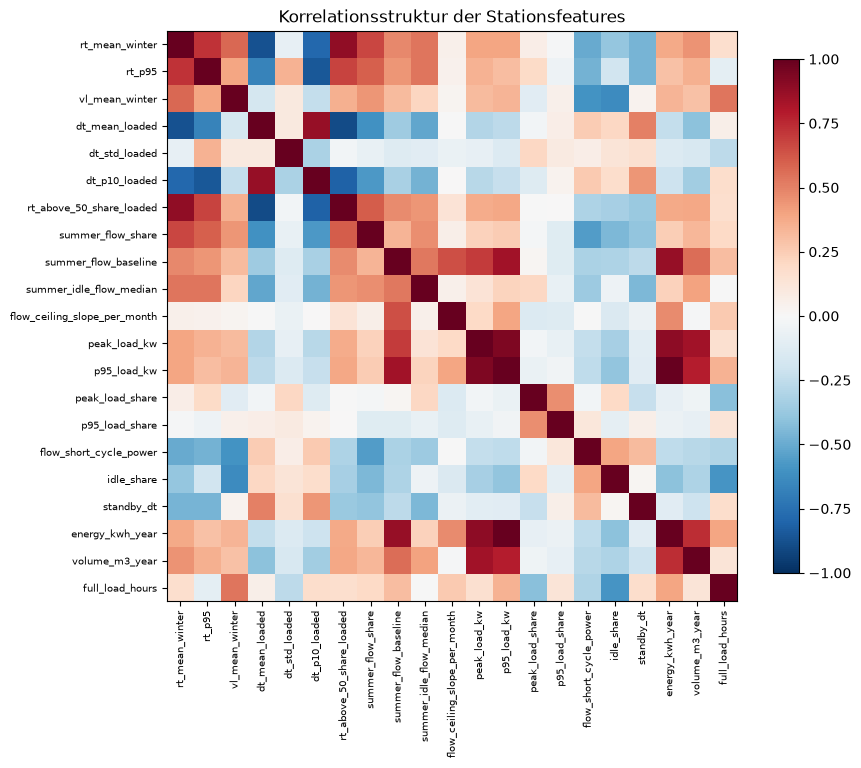

Paare mit |r| >= 0,8 - jedes davon zählt in der Distanz doppelt:


,Feature A,Feature B,r
11,p95_load_kw,energy_kwh_year,0.99
8,peak_load_kw,p95_load_kw,0.93
4,dt_mean_loaded,rt_above_50_share_loaded,-0.90
9,peak_load_kw,energy_kwh_year,0.90
1,rt_mean_winter,rt_above_50_share_loaded,0.89
7,summer_flow_baseline,energy_kwh_year,0.87
3,dt_mean_loaded,dt_p10_loaded,0.87
0,rt_mean_winter,dt_mean_loaded,-0.87
2,rt_p95,dt_p10_loaded,-0.85
6,summer_flow_baseline,p95_load_kw,0.84


In [15]:
korr = Xs.corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(korr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=90, fontsize=7)
ax.set_yticks(range(len(NUM)), NUM, fontsize=7)
ax.set_title("Korrelationsstruktur der Stationsfeatures")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

oben = np.triu(np.ones(korr.shape), 1).astype(bool)
paare = [{"Feature A": korr.index[i], "Feature B": korr.columns[j], "r": korr.iat[i, j]}
         for i, j in zip(*np.where((korr.abs() >= 0.8) & oben))]
print("Paare mit |r| >= 0,8 - jedes davon zählt in der Distanz doppelt:")
display(pd.DataFrame(paare).sort_values("r", key=lambda s: s.abs(), ascending=False).round(2))

In [16]:
#Achsen, mit denen die Fehlerrangliste arbeitet, bleiben bevorzugt drin
PRIORITAET = ["rt_mean_winter", "dt_mean_loaded", "summer_flow_baseline", "idle_share",
              "full_load_hours", "flow_short_cycle_power", "peak_load_share",
              "flow_ceiling_slope_per_month", "dt_std_loaded"]
auswahl, bilanz = cvl.redundanz_auswahl(Xs, schwelle=0.8, prioritaet=PRIORITAET)
print(f"{len(auswahl)} von {len(NUM)} Features bleiben:")
print(auswahl)
print("\nVerworfen, mit Grund:")
display(bilanz.round(2))

varianten = cvl.gewichtungsvarianten(Xs, NUM, auswahl=auswahl, pca_varianz=0.9)
for name, M in varianten.items():
    print(f"{name:14s} {M.shape[1]} Dimensionen")

15 von 21 Features bleiben:
['rt_mean_winter', 'summer_flow_baseline', 'idle_share', 'full_load_hours', 'flow_short_cycle_power', 'peak_load_share', 'flow_ceiling_slope_per_month', 'dt_std_loaded', 'rt_p95', 'vl_mean_winter', 'summer_flow_share', 'summer_idle_flow_median', 'peak_load_kw', 'p95_load_share', 'standby_dt']

Verworfen, mit Grund:


,feature,redundant_zu,korrelation
0,dt_mean_loaded,rt_mean_winter,0.87
1,dt_p10_loaded,rt_p95,0.85
2,rt_above_50_share_loaded,rt_mean_winter,0.89
3,p95_load_kw,summer_flow_baseline,0.84
4,energy_kwh_year,summer_flow_baseline,0.87
5,volume_m3_year,peak_load_kw,0.84


alle gleich    21 Dimensionen
auswahl        15 Dimensionen
pca            8 Dimensionen


In [17]:
def fit_station(M, k):
    return KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(M).labels_


TRIO = {58202380, 66761022, 86792512}
zaehler = feat["Zählernummer"].to_numpy()

zeilen = []
for name, M in varianten.items():
    for k in (2, 3, 4, 5):
        lab = fit_station(M, k)
        r = cvl.bootstrap_ari(fit_station, M, k, n_boot=25)
        groessen = pd.Series(lab).value_counts().sort_index()
        kleinstes = groessen.idxmin()
        zeilen.append({
            "Weg": name, "k": k,
            "Silhouette": silhouette_score(M, lab),
            "Bootstrap-ARI": r["ari_mean"],
            "Clustergrößen": "/".join(str(int(v)) for v in groessen),
            "Trio im kleinsten Cluster": len(set(zaehler[lab == kleinstes]) & TRIO),
        })
vergleich = pd.DataFrame(zeilen)
display(vergleich.round(3))

,Weg,k,Silhouette,Bootstrap-ARI,Clustergrößen,Trio im kleinsten Cluster
0,alle gleich,2,0.610,0.500,89/4,2
1,alle gleich,3,0.261,0.865,4/59/30,2
2,alle gleich,4,0.164,0.565,27/25/37/4,2
3,alle gleich,5,0.176,0.623,22/3/25/1/42,0
4,auswahl,2,0.308,0.587,24/69,2
5,auswahl,3,0.272,0.532,3/66/24,2
6,auswahl,4,0.177,0.594,17/3/27/46,2
7,auswahl,5,0.194,0.652,16/21/3/52/1,0
8,pca,2,0.636,0.522,89/4,2
9,pca,3,0.307,0.852,60/29/4,2


In [18]:
ACHSEN = ["rt_mean_winter", "dt_mean_loaded", "summer_flow_baseline", "idle_share"]
referenz = fit_station(varianten["alle gleich"], 3)
for name, M in varianten.items():
    lab = fit_station(M, 3)
    p = feat.assign(cluster=lab).groupby("cluster")[ACHSEN].median()
    p["n_hast"] = pd.Series(lab).value_counts().sort_index()
    print(f"--- {name}, k=3, ARI gegen 'alle gleich': "
          f"{adjusted_rand_score(referenz, lab):.3f}")
    display(p.round(2))

--- alle gleich, k=3, ARI gegen 'alle gleich': 1.000


,rt_mean_winter,dt_mean_loaded,summer_flow_baseline,idle_share,n_hast
cluster,,,,,
0,64.25,9.97,2102.5,0.02,4
1,41.59,28.45,0.0,0.35,59
2,53.47,17.44,42.0,0.25,30


--- auswahl, k=3, ARI gegen 'alle gleich': 0.651


,rt_mean_winter,dt_mean_loaded,summer_flow_baseline,idle_share,n_hast
cluster,,,,,
0,61.88,11.63,2270.0,0.01,3
1,42.72,27.74,0.0,0.34,66
2,54.54,16.55,69.5,0.25,24


--- pca, k=3, ARI gegen 'alle gleich': 0.959


,rt_mean_winter,dt_mean_loaded,summer_flow_baseline,idle_share,n_hast
cluster,,,,,
0,41.88,28.35,0.0,0.35,60
1,53.49,17.16,42.0,0.25,29
2,64.25,9.97,2102.5,0.02,4


- Zwölf Merkmalspaare mit |r| ≥ 0,8, vor allem die Größenachse (Jahresenergie, Leistung, Volumen) und die Auskühlung.
- k = 3: alle gleich Silhouette 0,261 und ARI 0,865, Auswahl (15 Merkmale) 0,272 und 0,532, PCA (8 Komponenten) 0,307 und 0,852.
- PCA ergibt fast dieselbe Partition wie „alle gleich“ (ARI 0,96), ist aber schlechter lesbar. Die Auswahl verschiebt sie (ARI 0,65).
- Bei k = 2 trennen „alle gleich“ und PCA nur die vier extremsten Stationen ab (89/4, Silhouette über 0,6).
- Ab k = 3 liegen alle Wege unter Silhouette 0,35. Die beiden Ausreißer 58202380 und 66761022 sitzen im kleinsten Cluster, der Rest ist ein Kontinuum. Die Gewichtung erklärt nicht die fehlenden Stationstypen.

## 9 Stationstypen und Leistungsklassen

- Zähler 86792512 ist laut `Zuordnung.xlsx` ein BHKW (Blockheizkraftwerk) und gehörte früher zum Ausreißer-Trio. Notebook 00 nimmt es inzwischen raus; die Zellen hier prüfen nur noch, dass es fehlt.
- Leistungsklassen über den Anschlusswert (`Nodes_Edges.ods`) mit Grenzen bei 5 und 10 kW; die Parameter stehen in `src/clustervalidierung.py`.

In [19]:
feat = cvl.mit_leistungsklasse(feat)
display(feat["leistungsklasse"].value_counts().sort_index().to_frame("Anzahl HAST"))
display(feat.groupby("leistungsklasse", observed=False)["anschlusswert_kw"]
        .describe().round(1))

vpin = pd.concat([pd.read_excel(ZUORDNUNG_PATH, sheet_name=s, dtype={"V-PIN": str})
                  [["Zählernummer", "V-PIN"]] for s in ("2024", "2025")])
vpin["Zählernummer"] = pd.to_numeric(vpin["Zählernummer"], errors="coerce")
bhkw = set(vpin.loc[vpin["V-PIN"] == "BHKW", "Zählernummer"].dropna().astype(int))
print("Als BHKW geführt:", sorted(bhkw))
display(feat.loc[feat["Zählernummer"].isin(bhkw),
                 ["Zählernummer", "anschlusswert_kw", "leistungsklasse",
                  "rt_mean_winter", "dt_mean_loaded", "energy_kwh_year"]].round(1))

,Anzahl HAST
leistungsklasse,
bis 5 kW,1
5-10 kW,52
über 10 kW,32
unbekannt,8


,count,mean,std,min,25%,50%,75%,max
leistungsklasse,,,,,,,,
bis 5 kW,1.0,5.0,NaN,5.0,5.0,5.0,5.0,5.0
5-10 kW,52.0,8.6,1.1,6.0,8.0,8.0,10.0,10.0
über 10 kW,32.0,31.6,85.8,11.0,12.8,14.0,17.5,500.0
unbekannt,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Als BHKW geführt: [86792512]


,Zählernummer,anschlusswert_kw,leistungsklasse,rt_mean_winter,dt_mean_loaded,energy_kwh_year


- Bis 5 kW 1 Station, 5 bis 10 kW 52, über 10 kW 32, ohne Anschlusswert 8.
- Nutzbar sind zwei Klassen plus die Gruppe ohne Anschlusswert. Die Grenzen sind noch fachlich festzulegen.

In [20]:
ohne_bhkw = (~feat["Zählernummer"].isin(bhkw)).to_numpy()
zeilen = []
for name, maske in [("alle Stationen", np.ones(len(feat), bool)), ("ohne BHKW", ohne_bhkw)]:
    M = StandardScaler().fit_transform(Xs[maske][auswahl])
    for k in (2, 3, 4):
        lab = fit_station(M, k)
        r = cvl.bootstrap_ari(fit_station, M, k, n_boot=25)
        zeilen.append({"Gruppe": name, "n": int(maske.sum()), "k": k,
                       "Silhouette": silhouette_score(M, lab),
                       "Bootstrap-ARI": r["ari_mean"],
                       "Clustergrößen": "/".join(str(int(v)) for v in
                                                 pd.Series(lab).value_counts().sort_index())})

for klasse in feat["leistungsklasse"].cat.categories:
    maske = (feat["leistungsklasse"] == klasse).to_numpy() & ohne_bhkw
    if maske.sum() < 15:
        zeilen.append({"Gruppe": f"nur {klasse}", "n": int(maske.sum()), "k": np.nan,
                       "Silhouette": np.nan, "Bootstrap-ARI": np.nan,
                       "Clustergrößen": "zu klein zum Clustern"})
        continue
    M = StandardScaler().fit_transform(Xs[maske][auswahl])
    for k in (2, 3):
        lab = fit_station(M, k)
        r = cvl.bootstrap_ari(fit_station, M, k, n_boot=25)
        zeilen.append({"Gruppe": f"nur {klasse}", "n": int(maske.sum()), "k": k,
                       "Silhouette": silhouette_score(M, lab),
                       "Bootstrap-ARI": r["ari_mean"],
                       "Clustergrößen": "/".join(str(int(v)) for v in
                                                 pd.Series(lab).value_counts().sort_index())})
display(pd.DataFrame(zeilen).round(3))

,Gruppe,n,k,Silhouette,Bootstrap-ARI,Clustergrößen
0,alle Stationen,93,2.0,0.308,0.587,24/69
1,alle Stationen,93,3.0,0.272,0.532,3/66/24
2,alle Stationen,93,4.0,0.177,0.594,17/3/27/46
3,ohne BHKW,93,2.0,0.308,0.587,24/69
4,ohne BHKW,93,3.0,0.272,0.532,3/66/24
5,ohne BHKW,93,4.0,0.177,0.594,17/3/27/46
6,nur bis 5 kW,1,NaN,NaN,NaN,zu klein zum Clustern
7,nur 5-10 kW,52,2.0,0.254,0.501,39/13
8,nur 5-10 kW,52,3.0,0.154,0.356,25/26/1
9,nur über 10 kW,32,2.0,0.255,0.398,20/12


In [21]:
M = StandardScaler().fit_transform(Xs[ohne_bhkw][auswahl])
lab3 = fit_station(M, 3)
tab = pd.crosstab(pd.Series(lab3, name="cluster"),
                  feat.loc[ohne_bhkw, "leistungsklasse"].astype(str))
print("Cluster gegen Leistungsklasse, ohne BHKW, k=3:")
display(tab)
print(f"Cramers V: {cvl.cramers_v(tab):.3f}")

Cluster gegen Leistungsklasse, ohne BHKW, k=3:


leistungsklasse,5-10 kW,bis 5 kW,unbekannt,über 10 kW
cluster,,,,
0,0,0,2,1
1,43,1,5,17
2,9,0,1,14


Cramers V: 0.347


## 10 Leistungsklassen auf Stundenebene

- Auf Stundenebene stehen je Klasse rund 100 000 bis 960 000 Stunden zur Verfügung.
- Vorab der Lauf ohne BHKW.

In [22]:
print("BHKW im Stundenpanel:", sorted(set(panel["Zählernummer"]) & bhkw))
panel_ob = panel[~panel["Zählernummer"].isin(bhkw)]
X_ob = StandardScaler().fit_transform(panel_ob[F])
lab_ob = cvl.fit_minibatch_kmeans(X_ob, K, n_init=10)
print(f"Stundencluster ohne BHKW: {len(panel_ob):,} Stunden, "
      f"Silhouette {cvl.silhouette_stichprobe(X_ob, lab_ob, 20000):.3f}, "
      f"ARI gegen den Lauf mit BHKW {adjusted_rand_score(panel.loc[panel_ob.index, 'cluster'], lab_ob):.3f}")

klassen_map = feat.set_index("Zählernummer")["leistungsklasse"].astype(str)
panel_ob = panel_ob.assign(leistungsklasse=panel_ob["Zählernummer"].map(klassen_map))
display(panel_ob["leistungsklasse"].value_counts().to_frame("Stunden"))

for klasse in panel_ob["leistungsklasse"].dropna().unique():
    maske = panel_ob["leistungsklasse"] == klasse
    if maske.sum() < 50000:
        print(f"[{klasse}] {int(maske.sum()):,} Stunden - zu wenig, übersprungen")
        continue
    Mk = StandardScaler().fit_transform(panel_ob.loc[maske, F])
    lk = cvl.fit_minibatch_kmeans(Mk, K, n_init=10)
    rk = cvl.bootstrap_ari(fit_stunden, Mk, K, n_boot=15, stichprobe=40000)
    print(f"--- {klasse}: {int(maske.sum()):,} Stunden, "
          f"Silhouette {cvl.silhouette_stichprobe(Mk, lk, 20000):.3f}, "
          f"Bootstrap-ARI {rk['ari_mean']:.3f}")
    display(cvl.zentroid_profil(panel_ob.loc[maske, F].to_numpy(), lk, F).round(2))

BHKW im Stundenpanel: []


Stundencluster ohne BHKW: 1,676,633 Stunden, Silhouette 0.399, ARI gegen den Lauf mit BHKW 1.000


,Stunden
leistungsklasse,
5-10 kW,1007834
über 10 kW,565959
unbekannt,86716
bis 5 kW,16124


--- über 10 kW: 565,959 Stunden, Silhouette 0.407, Bootstrap-ARI 0.800


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.37,0.26,34.23,71.32,37.05,129580,22.9
1,0.00,0.01,3.72,37.60,33.85,79914,14.1
2,0.15,0.77,2.60,75.98,73.35,105926,18.7
3,0.89,0.84,23.21,74.70,51.45,102453,18.1
4,0.08,0.11,13.62,68.42,54.76,148086,26.2


--- unbekannt: 86,716 Stunden, Silhouette 0.408, Bootstrap-ARI 0.738


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.07,0.13,9.52,74.92,65.36,16635,19.2
1,0.32,0.25,32.74,70.86,38.07,27675,31.9
2,0.00,0.01,4.68,39.35,34.64,17221,19.9
3,0.59,0.65,12.97,76.45,63.45,13636,15.7
4,0.97,0.89,25.76,74.59,48.78,11549,13.3


--- 5-10 kW: 1,007,834 Stunden, Silhouette 0.412, Bootstrap-ARI 0.768


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.31,0.20,33.62,64.96,31.30,266615,26.5
1,0.08,0.10,11.39,65.03,53.60,251836,25.0
2,0.00,0.01,3.23,35.24,31.99,225236,22.3
3,0.91,0.87,22.99,72.64,49.61,165817,16.5
4,0.26,0.80,5.31,73.86,68.50,98330,9.8


[bis 5 kW] 16,124 Stunden - zu wenig, übersprungen


Stundenebene
- Das BHKW ist schon in Notebook 00 raus, beide Läufe sind gleich (Silhouette 0,399, ARI 1,0).
- Je Klasse Silhouette 0,407 bis 0,412 und dieselben fünf Zustände inklusive Kurzschlussverdacht, weil die Objektgröße durch die Normierung schon herausgerechnet ist.

Stationsebene
- Je Klasse Silhouette 0,154 bis 0,255 gegen 0,308 für alle Stationen zusammen; Cramérs V Cluster gegen Klasse 0,347.
- Die Leistungsklasse taugt als Kontext, nicht als Trennlinie.

## 11 Export

- Anteile je Station und Cluster nach `data/processed/clustervalidierung.csv` (keine Stundenreihe).
- Lauf-Kontext als JSON daneben.

In [23]:
out_path = ROOT / "data" / "processed" / "clustervalidierung.csv"
export = anteile.copy()
export.index.name = "Zählernummer"
export = export.reset_index()
export = export.merge(feat[["Zählernummer", "leistungsklasse"]], on="Zählernummer", how="left")
export["ist_bhkw"] = export["Zählernummer"].isin(bhkw)
export.to_csv(out_path, index=False)

meta = {
    "erzeugt": pd.Timestamp.now().isoformat(timespec="seconds"),
    "quelle": "data/processed/real_meters (Notebook 00, mit ODS-Nachlieferung)",
    "stunden": int(len(panel)),
    "zaehler": int(panel["Zählernummer"].nunique()),
    "k_stunden": K,
    "random_state": SEED,
    "merkmale_stunden": F,
    "silhouette_stunden": round(float(sil_voll), 4),
    "bootstrap_ari_stunden": round(float(ari_stunden), 4),
    "silhouette_kernwinter": round(float(sil_w), 4),
    "bootstrap_ari_kernwinter": round(float(r_w["ari_mean"]), 4),
    "kontext_erklaerbarkeit": erklaerbarkeit.round(4).to_dict("records"),
    "gewichtungsvergleich": vergleich.round(4).to_dict("records"),
    "redundanz_schwelle": 0.8,
    "auswahl_features": auswahl,
    "verworfene_features": bilanz.round(3).to_dict("records"),
    "leistungsklassen_grenzen": list(cvl.LEISTUNGSKLASSEN_GRENZEN),
    "bhkw_zaehler": sorted(int(z) for z in bhkw),
}
meta_path = out_path.with_suffix(".json")
meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Anteile je Station -> {out_path}")
print(f"Lauf-Kontext       -> {meta_path}")

Anteile je Station -> /Users/ivelinayaneva/projektseminar/data/processed/clustervalidierung.csv
Lauf-Kontext       -> /Users/ivelinayaneva/projektseminar/data/processed/clustervalidierung.json


## Zusammenfassung & Bewertung

**Ergebnis**
- Die Stundencluster sind stabil: k = 5, Silhouette 0,399, Bootstrap-ARI 0,851.
- Empfehlung für die Fehlererkennung: K-Means auf Stundenebene, k = 5, ganzes Jahr, die fünf Merkmale mit StandardScaler, Saison und Leistungsklasse als Kontext.
- Fehlerrangliste über den Zeitanteil im Kurzschlusszustand.
- Stationstypisierung: k = 3 auf der redundanzbereinigten Auswahl, wegen der Lesbarkeit.

**Belastbar**
- Kein Jahreszeiten- oder Tag-Nacht-Artefakt: Die Witterung holt 19 % des Abstands, Cramérs V zur Stunde 0,101.
- Der Kurzschlussverdacht (13 % der Stunden) ist saisonneutral und auch im Kernwinter erkennbar, dort in reiner Form ab k = 7. Das ist der stärkste Einzelbefund.
- Leistungsklassen ändern die Stundenzustände kaum.

**Schwach**
- Die Saison prägt drei der fünf Zustände; im Kernwinter allein Silhouette 0,285 und ARI 0,474.
- k = 4 und k = 5 sind fast gleich stabil (0,805 und 0,851); k = 5 stützt sich auf Silhouette und Lesbarkeit.
- Der Abgleich mit den Begehungen bleibt ohne p < 0,05. Bei nur 13 Stationen ohne Maßnahme ist das zu erwarten.
- Die Stationsebene bleibt ein Kontinuum mit zwei Ausreißern, unabhängig von der Gewichtung.

**Offen**
- Korrelationsschwelle und Prioritätsliste, Klassengrenzen, Umgang mit Stationen ohne Anschlusswert, Wahl zwischen k = 4 und k = 5.
- Der Kurzschlussverdacht ist nur „konsistent mit“ einem Defekt; ein Nachweis braucht eine Prüfung vor Ort.